# 06 — EMOS on rolling training windows

*27 Nov 2026.* The censored-normal EMOS refitted for every validation issue D on the observations known at D's
issue time: issues up to **D−3** (the last whose target day is fully observed by 09Z on D), over a window of
30, 90 or 365 calendar days, or all history (expanding). The 30- and 90-day windows pool hours h−1, h, h+1.
Each refit starts from the previous issue's parameters. Compared with static EMOS (fitted once on the train
fold), the raw ensemble and climatology. **Validation fold only.**

1. Scores: CRPS, CRPSS against climatology, coverage
2. Calibration per zone: does the val bias in NO3 / NO4 shrink with shorter windows?
3. Stability of the coefficients over time (weekly refits over the train and val periods)

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from windai.data.build import load_dataset
from windai.data.splits import training_rows, evaluation_rows, history_rows
from windai.models.EMOS import EMOS, RollingEMOS
from windai.models.baselines import Climatology, RawEnsemble
from windai.evaluation.evaluate import score

pd.set_option("display.width", 200)
df, curve = load_dataset("train", fit="val")
train, history, val = training_rows(df, "val"), history_rows(df, "val"), evaluation_rows(df, "val")
hidden = val.drop(columns=["power", "cf"])
y = val["power"].to_numpy()

models = {"climatology": (Climatology(), train), "raw_ensemble": (RawEnsemble(), train), "emos_static": (EMOS(), train)}
for w in (30, 90, 365, None):
    m = RollingEMOS(w)
    models[m.name] = (m, history)
fc, seconds = {}, {}
for name, (model, data) in models.items():
    t0 = time.time()
    fc[name] = model.fit(data).predict(hidden)
    seconds[name] = time.time() - t0
pd.Series(seconds, name="seconds").round(1)

climatology           0.5
raw_ensemble          0.1
emos_static           1.2
emos_rolling_30     162.5
emos_rolling_90     191.5
emos_rolling_365    181.1
emos_expanding      206.7
Name: seconds, dtype: float64

## 1. Scores on val

In [2]:
rows = {}
for name, f in fc.items():
    t = score(f, y).loc["all"]
    rows[name] = t
overall = pd.DataFrame(rows).T
clim = overall.loc["climatology", "crps_q"]
overall["crpss"] = 1 - overall["crps_q"] / clim
cols = ["crps_q", "crps_exact", "crpss", "rmse", "cov_50", "cov_80", "cov_90", "cov_95"]
overall[[c for c in cols if c in overall.columns]].round(3)

,crps_q,crps_exact,crpss,rmse,cov_50,cov_80,cov_90,cov_95
climatology,166.565,NaN,0.000,331.300,0.477,0.778,0.885,0.936
raw_ensemble,90.319,NaN,0.458,168.755,0.223,0.389,0.465,0.510
emos_static,80.004,79.223,0.520,164.172,0.568,0.851,0.921,0.957
emos_rolling_30,78.499,77.745,0.529,161.379,0.477,0.758,0.851,0.901
emos_rolling_90,77.507,76.757,0.535,160.654,0.516,0.810,0.889,0.932
emos_rolling_365,78.192,77.433,0.531,161.792,0.539,0.834,0.909,0.946
emos_expanding,79.310,78.536,0.524,163.020,0.567,0.850,0.921,0.956


In [3]:
per_zone = pd.DataFrame({name: score(f, y)["crps_q"] for name, f in fc.items()})
crpss_zone = 1 - per_zone.div(per_zone["climatology"], axis=0)
crpss_zone.drop(columns="climatology").round(3)

,raw_ensemble,emos_static,emos_rolling_30,emos_rolling_90,emos_rolling_365,emos_expanding
zone,,,,,,
ELSPOT NO1,0.205,0.365,0.335,0.349,0.335,0.365
ELSPOT NO2,0.529,0.577,0.581,0.590,0.588,0.579
ELSPOT NO3,0.489,0.529,0.530,0.533,0.530,0.532
ELSPOT NO4,0.358,0.457,0.507,0.509,0.504,0.468
all,0.458,0.520,0.529,0.535,0.531,0.524


### Findings (1)
- **The 90-day window is best:** CRPS 77.5 MW against 80.0 for static EMOS (−3.1 %), CRPSS 0.535 against 0.520,
  and coverage closest to nominal (52 / 81 / 89 / 93 % at 50 / 80 / 90 / 95 %).
- **Window length trades bias against estimation noise.** 30 days is slightly too narrow (90 % interval: 85 %),
  365 days is in between, and the expanding window behaves almost exactly like static EMOS (CRPSS 0.524).
- **By zone:** NO4 gains most (0.457 → 0.509), the zone where static EMOS underpredicted on val. NO2 and NO3
  gain a little. **NO1 loses** with every limited window (0.365 → 0.335–0.349): in the smallest, noisiest zone,
  estimation noise outweighs the benefit of recent data.
- Runtime: 2.5–3.5 min per window on val (~34k fits each, warm-started, analytic gradient).

## 2. Calibration per zone (randomised PIT)

In [4]:
obs = ~np.isnan(y)
zones = val["zone"].to_numpy()[obs]
emos_names = [n for n in fc if n.startswith("emos")]
pit = {n: fc[n].pit_fn(y[obs], rng=0) for n in emos_names}
summ = {}
for n in emos_names:
    for z in sorted(set(zones)):
        p = pit[n][zones == z]
        summ[(n, z)] = {"mean PIT": p.mean(), "outer tenths": ((p < 0.1) | (p > 0.9)).mean(),
                        "middle fifth": ((p > 0.4) & (p < 0.6)).mean()}
pit_table = pd.DataFrame(summ).T
pit_table["mean PIT"].unstack(0).round(3)

,emos_expanding,emos_rolling_30,emos_rolling_365,emos_rolling_90,emos_static
ELSPOT NO1,0.502,0.486,0.446,0.474,0.504
ELSPOT NO2,0.535,0.496,0.508,0.504,0.535
ELSPOT NO3,0.447,0.491,0.456,0.484,0.436
ELSPOT NO4,0.588,0.500,0.523,0.502,0.598


In [5]:
pit_table["outer tenths"].unstack(0).round(3)

,emos_expanding,emos_rolling_30,emos_rolling_365,emos_rolling_90,emos_static
ELSPOT NO1,0.136,0.243,0.149,0.177,0.133
ELSPOT NO2,0.163,0.247,0.172,0.201,0.161
ELSPOT NO3,0.126,0.226,0.148,0.178,0.123
ELSPOT NO4,0.176,0.251,0.195,0.206,0.181


### Findings (2)
- **Shorter windows remove the val bias.** The mean PIT in NO3 moves from 0.436 (static) to 0.484 (90 d) and in
  NO4 from 0.598 to 0.502. With a calibrated forecast it would be 0.5.
- **The 90-day window also fixes the width.** The outer-tenths share is 0.18–0.21 (static: 0.12–0.18, i.e. too
  wide; 30 d: 0.23–0.25, slightly too narrow; calibrated: 0.20).
- In NO1, the 365-day window shifts the mean PIT to 0.446, which matches its weaker CRPS there.

## 3. Stability of the coefficients over time
Refits for one issue per week over the train and val periods (the train period is used here only as a
diagnostic; nothing is scored there). Shown: the median over the 24 hourly models of each zone.

230 s for 201 weekly refits x 2 windows


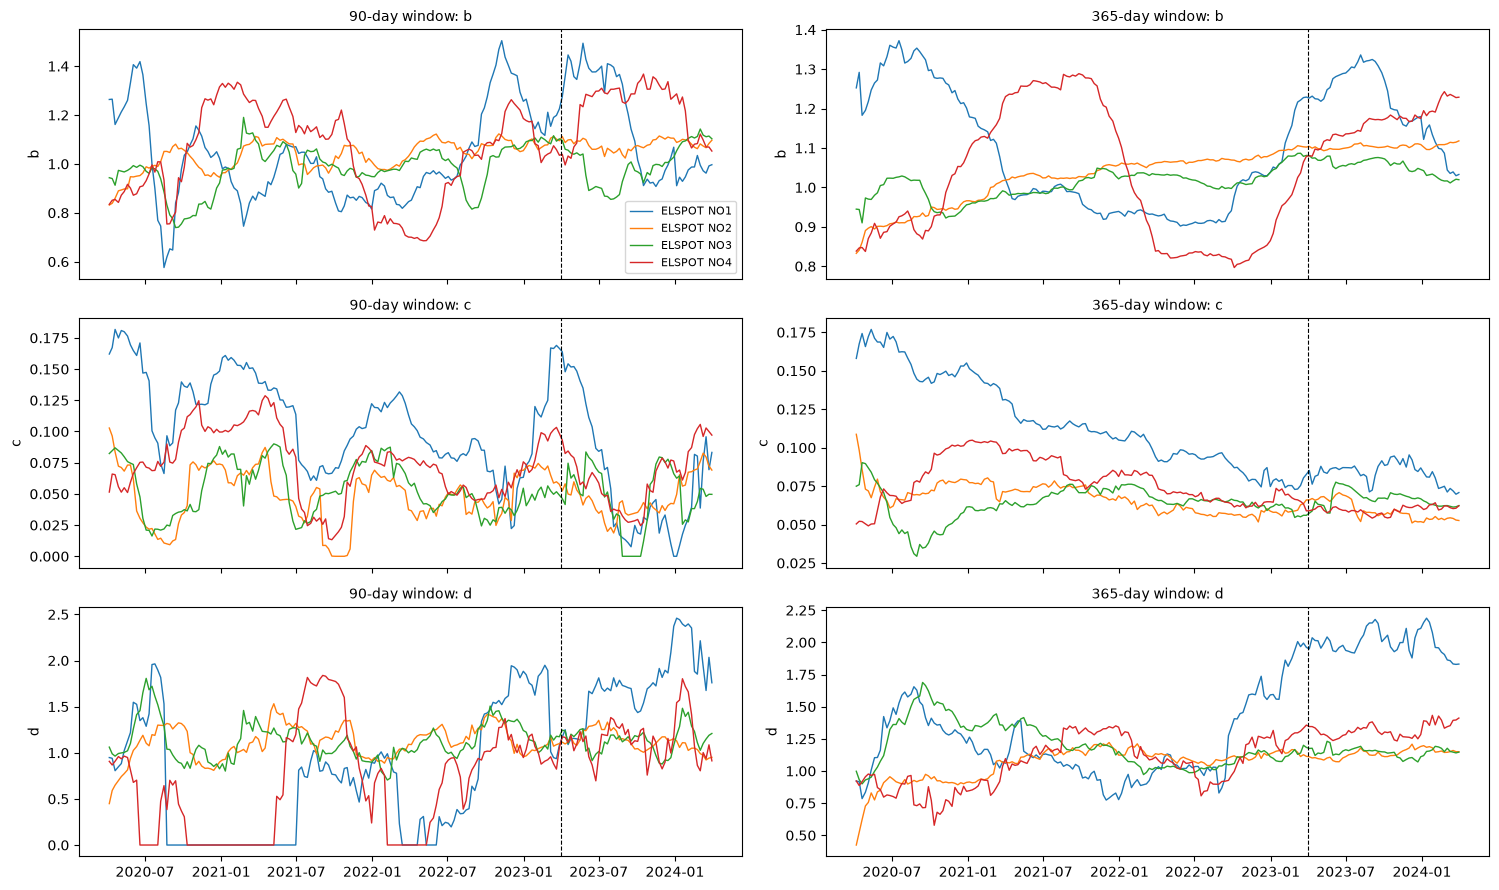

In [6]:
issue_days = np.sort(df.loc[df["fold"].isin(["train", "val"]), "issue_date"].unique())
weekly = issue_days[::7][7:]                                   # skip the first weeks (too little history)
rows_weekly = df.loc[df["issue_date"].isin(weekly)].drop(columns=["power", "cf"])
stab = {}
t0 = time.time()
for w in (90, 365):
    m = RollingEMOS(w).fit(history)
    m.predict(rows_weekly)
    stab[w] = m.params_by_issue
print(f"{time.time() - t0:.0f} s for {len(weekly)} weekly refits x 2 windows")

fig, axes = plt.subplots(3, 2, figsize=(15, 9), sharex=True)
for j, w in enumerate((90, 365)):
    med = stab[w].groupby(["issue_date", "zone"])[["b", "c", "d"]].median().reset_index()
    for i, col in enumerate(["b", "c", "d"]):
        for zone, g in med.groupby("zone"):
            axes[i, j].plot(pd.to_datetime(g["issue_date"]), g[col], label=zone, lw=1)
        axes[i, j].axvline(pd.Timestamp("2023-04-01"), color="k", ls="--", lw=0.8)
        axes[i, j].set_ylabel(col); axes[i, j].set_title(f"{w}-day window: {col}", fontsize=10)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [7]:
# Spread of the coefficients over time: SD over weeks of the zone medians, and the fallback share
for w in (90, 365):
    med = stab[w].groupby(["issue_date", "zone"])[["a", "b", "c", "d"]].median()
    print(f"{w}-day window, SD over weeks:")
    print(med.groupby("zone").std().round(3))
    print("fallback share:", round(float(stab[w]["fallback"].mean()), 4), "| min values per fit:", int(stab[w]["n"].min()))

90-day window, SD over weeks:
                a      b      c      d
zone                                  
ELSPOT NO1  0.044  0.201  0.045  0.756
ELSPOT NO2  0.027  0.058  0.021  0.168
ELSPOT NO3  0.031  0.091  0.022  0.187
ELSPOT NO4  0.023  0.190  0.026  0.553
fallback share: 0.0 | min values per fit: 140
365-day window, SD over weeks:
                a      b      c      d
zone                                  
ELSPOT NO1  0.033  0.149  0.029  0.428
ELSPOT NO2  0.013  0.068  0.009  0.122
ELSPOT NO3  0.025  0.039  0.010  0.157
ELSPOT NO4  0.018  0.162  0.015  0.207
fallback share: 0.0 | min values per fit: 46


### Findings (3): stationarity
- **The relationship between forecast and power drifts over time, and the drift differs by zone.**
  - **NO2 and NO3 are fairly stable** with a 365-day window: b moves slowly from about 0.9–1.0 to 1.1, and
    c slowly falls.
  - **NO4's slope b swings strongly** (365-day window: ~0.85 → ~1.3 in 2021, ~0.8 in late 2022, back to ~1.2;
    the 90-day window shows the first rise already from late 2020). NO4 had two large additions: Raudfjell
    (84 MW, Aug 2020) and Øyfjell1/2 (400 MW, Aug/Oct 2021). The first rise fits them, so a **composition effect**
    (new parks changing how the zone responds, which capacity factor doesn't remove) is a plausible part of the
    drift. But the dip in 2022 and the rise in 2023 have no matching capacity change (only 54 MW added in late
    2022), so other causes (weather regimes, curtailment, the power curve averaging over changing compositions)
    must contribute. This is a hypothesis to test, not an explanation.
  - **NO1 also swings in b** (0.9–1.35) and its base SD c falls steadily (0.17 → 0.07), as the zone grows from
    a few parks to more. More parks average out park-level noise.
- **With 90-day windows the coefficients are noisy, with a seasonal pattern.** d often collapses to 0 in NO1
  and NO4, i.e. within 90 days the spread carries no information there and the variance comes from c alone.
- **Consequence for the thesis:** the conditional-stationarity assumption holds approximately for NO2 and NO3
  but clearly not for NO4 and NO1, where training windows (or covariates for composition) are needed. The gain
  from 90-day windows on val is the practical side of the same finding, and a first indication for H1:
  training length matters, in both directions.

## Summary
| | Result |
|---|---|
| Best window | **90 days**: CRPS 77.5 MW (−3.1 % vs static), CRPSS 0.535, coverage 52 / 81 / 89 / 93 % |
| Val bias | Removed with short windows (mean PIT NO3 0.44 → 0.48, NO4 0.60 → 0.50) |
| Calibration | 90 d close to calibrated; static too wide; 30 d slightly too narrow |
| Zone exception | NO1 is best with static or expanding fits; short windows add noise there |
| Stationarity | NO2/NO3 fairly stable; NO4 and NO1 drift (partly coinciding with park additions; not fully explained) |